# Reducción dimensional y benchmarking

En este notebook se analizan los resultados de los modelos no supervisados
K-Means y DBSCAN mediante técnicas de reducción dimensional.

Se utilizarán:

- PCA a dos dimensiones.
- t-SNE a dos dimensiones.
- Visualización de los clusters obtenidos.
- Comparación entre K-Means y DBSCAN.
- Benchmark de latencia de inferencia.

El objetivo es representar visualmente un dataset compuesto originalmente
por 24 variables de sensores ultrasónicos y evaluar posteriormente el
tiempo de inferencia de los modelos disponibles.

In [30]:
from pathlib import Path
from time import perf_counter
import json

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE


# Obtener automáticamente la raíz del proyecto.
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent


dataset_path = (
    project_root
    / "data"
    / "processed"
    / "dataset.parquet"
)

kmeans_path = (
    project_root
    / "models"
    / "kmeans.pkl"
)

dbscan_path = (
    project_root
    / "models"
    / "dbscan.pkl"
)

random_forest_path = (
    project_root
    / "models"
    / "random_forest.pkl"
)

svm_path = (
    project_root
    / "models"
    / "svm.pkl"
)

print("Raíz del proyecto:")
print(project_root)

Raíz del proyecto:
/mnt/DiscoD/U/MachineLearning/ml-practica1-zurita


## Carga del dataset y de los modelos no supervisados

Se utiliza el dataset previamente procesado y escalado.

Para el análisis de clustering se seleccionan únicamente las 24 variables
correspondientes a los sensores ultrasónicos.

Las columnas `Class` y `split` no participan en la formación de los clusters.
Los modelos K-Means y DBSCAN se cargan desde los archivos generados durante
la Clase 7.

In [31]:
SENSOR_COLUMNS = [
    f"US{i}"
    for i in range(1, 25)
]

df = pd.read_parquet(
    dataset_path
)

X = df[SENSOR_COLUMNS].copy()

kmeans_model = joblib.load(
    kmeans_path
)

dbscan_model = joblib.load(
    dbscan_path
)

kmeans_labels = kmeans_model.labels_
dbscan_labels = dbscan_model.labels_

print("Dimensiones de X:", X.shape)

print(
    "Clusters K-Means:",
    sorted(set(kmeans_labels))
)

print(
    "Etiquetas DBSCAN:",
    sorted(set(dbscan_labels))
)

Dimensiones de X: (5456, 24)
Clusters K-Means: [np.int32(0), np.int32(1), np.int32(2), np.int32(3)]
Etiquetas DBSCAN: [np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


## PCA a dos dimensiones

PCA (Principal Component Analysis) permite transformar las 24 variables
originales en un número menor de componentes principales.

En este análisis se utilizan dos componentes para representar cada
observación como un punto en un plano.

Las componentes principales buscan concentrar la mayor cantidad posible
de variabilidad presente en las variables originales.

Esta reducción se utiliza con fines de análisis y visualización y no
reemplaza el dataset original utilizado para entrenar los modelos.

In [32]:
pca = PCA(
    n_components=2
)

X_pca = pca.fit_transform(
    X
)

pca_df = pd.DataFrame(
    {
        "PC1": X_pca[:, 0],
        "PC2": X_pca[:, 1],
        "KMeans": kmeans_labels,
        "DBSCAN": dbscan_labels
    }
)

print(
    "Varianza explicada por PC1:",
    round(
        pca.explained_variance_ratio_[0],
        4
    )
)

print(
    "Varianza explicada por PC2:",
    round(
        pca.explained_variance_ratio_[1],
        4
    )
)

print(
    "Varianza explicada total:",
    round(
        pca.explained_variance_ratio_.sum(),
        4
    )
)

pca_df.head()

Varianza explicada por PC1: 0.3028
Varianza explicada por PC2: 0.1687
Varianza explicada total: 0.4716


,PC1,PC2,KMeans,DBSCAN
0,-2.112798,0.344279,2,0
1,4.091927,10.618614,0,0
2,-3.748760,-0.109754,2,0
3,-3.261633,-0.119751,2,0
4,-2.709011,0.188868,2,0


### Interpretación de la varianza explicada

La primera componente principal (`PC1`) explica aproximadamente el 30.28 %
de la variabilidad total del dataset, mientras que la segunda componente
principal (`PC2`) explica aproximadamente el 16.87 %.

En conjunto, las dos componentes utilizadas para la representación 2D
conservan aproximadamente el 47.16 % de la variabilidad presente en las
24 variables originales.

Esto permite visualizar una parte importante de la estructura del dataset,
pero también implica que aproximadamente el 52.84 % de la variabilidad
queda fuera de esta representación bidimensional.

Por esta razón, la superposición de puntos o clusters en la gráfica PCA
no debe interpretarse necesariamente como una ausencia de separación en
el espacio original de 24 dimensiones.

## Visualización PCA de K-Means

Se representan las observaciones utilizando las dos primeras componentes
principales.

Cada punto corresponde a una observación del dataset y el color representa
el cluster asignado por K-Means.

Esta visualización permite analizar cómo se distribuyen en dos dimensiones
los cuatro clusters encontrados previamente.

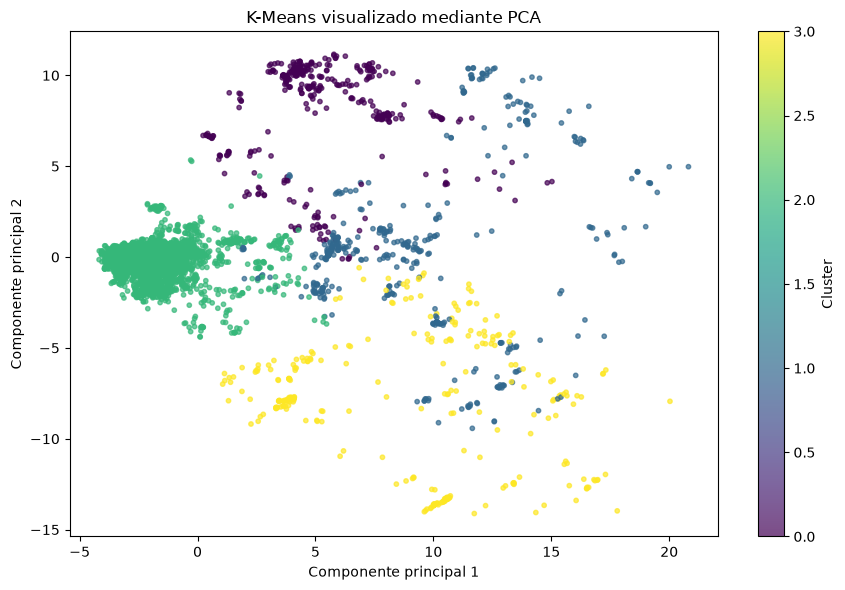

In [33]:
plt.figure(
    figsize=(9, 6)
)

scatter = plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["KMeans"],
    s=10,
    alpha=0.7
)

plt.title(
    "K-Means visualizado mediante PCA"
)

plt.xlabel(
    "Componente principal 1"
)

plt.ylabel(
    "Componente principal 2"
)

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.tight_layout()
plt.show()

## Visualización PCA de DBSCAN

Se utiliza la misma proyección PCA empleada para K-Means.

En este caso, el color de cada observación representa la etiqueta asignada
por DBSCAN.

La etiqueta `-1` corresponde a puntos que el algoritmo identificó como
ruido.

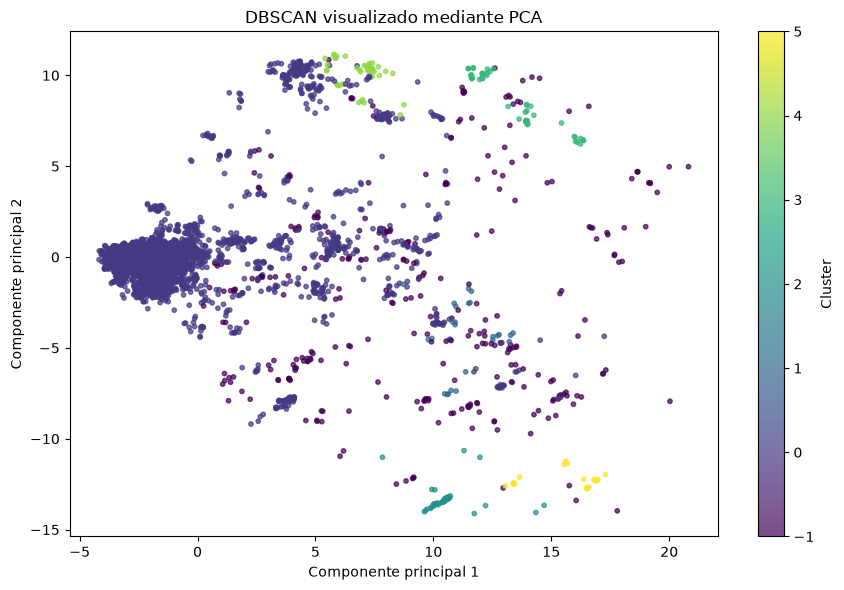

In [34]:
plt.figure(
    figsize=(9, 6)
)

scatter = plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["DBSCAN"],
    s=10,
    alpha=0.7
)

plt.title(
    "DBSCAN visualizado mediante PCA"
)

plt.xlabel(
    "Componente principal 1"
)

plt.ylabel(
    "Componente principal 2"
)

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.tight_layout()
plt.show()

### Interpretación de las visualizaciones PCA

La proyección PCA permite observar diferencias importantes entre los
resultados obtenidos por K-Means y DBSCAN.

En K-Means se distinguen varias regiones correspondientes a los cuatro
clusters encontrados. Aunque existe superposición en algunas zonas,
los grupos presentan una organización visual relativamente diferenciada.

En DBSCAN se observa una estructura distinta. La mayoría de las
observaciones pertenece a un único cluster dominante, mientras que
varios grupos pequeños aparecen en regiones más aisladas del espacio.

También existen observaciones identificadas como ruido mediante la
etiqueta `-1`.

Este comportamiento coincide con los resultados numéricos obtenidos
durante el entrenamiento, donde DBSCAN asignó 4960 observaciones a su
cluster principal y clasificó 308 observaciones como ruido.

Debe considerarse que las dos primeras componentes principales conservan
aproximadamente el 47.16 % de la variabilidad original. Por lo tanto,
la representación bidimensional no contiene toda la estructura existente
en el espacio original de 24 dimensiones.

## t-SNE a dos dimensiones

t-SNE es una técnica de reducción dimensional no lineal orientada a
preservar relaciones locales entre las observaciones.

A diferencia de PCA, t-SNE no busca maximizar la varianza explicada.
Su objetivo principal es colocar cerca en el espacio bidimensional
aquellas observaciones que también son similares en el espacio original.

Por esta razón resulta especialmente útil para visualizar agrupaciones
y estructuras locales presentes en datos de alta dimensionalidad.

Los ejes generados por t-SNE no poseen una interpretación directa como
ocurre con las componentes principales de PCA.

In [35]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    max_iter=1000,
    random_state=42
)

X_tsne = tsne.fit_transform(
    X
)

tsne_df = pd.DataFrame(
    {
        "TSNE1": X_tsne[:, 0],
        "TSNE2": X_tsne[:, 1],
        "KMeans": kmeans_labels,
        "DBSCAN": dbscan_labels
    }
)

tsne_df.head()

,TSNE1,TSNE2,KMeans,DBSCAN
0,-4.042315,50.714207,2,0
1,26.454163,66.367966,0,0
2,-22.285202,8.744078,2,0
3,-44.642719,-41.682003,2,0
4,-75.332787,-8.402048,2,0


### Visualización t-SNE - K-Means

Se representan los cuatro clusters encontrados por K-Means utilizando
las coordenadas obtenidas mediante t-SNE.

Esta representación permite analizar con mayor detalle la estructura
local de los grupos.

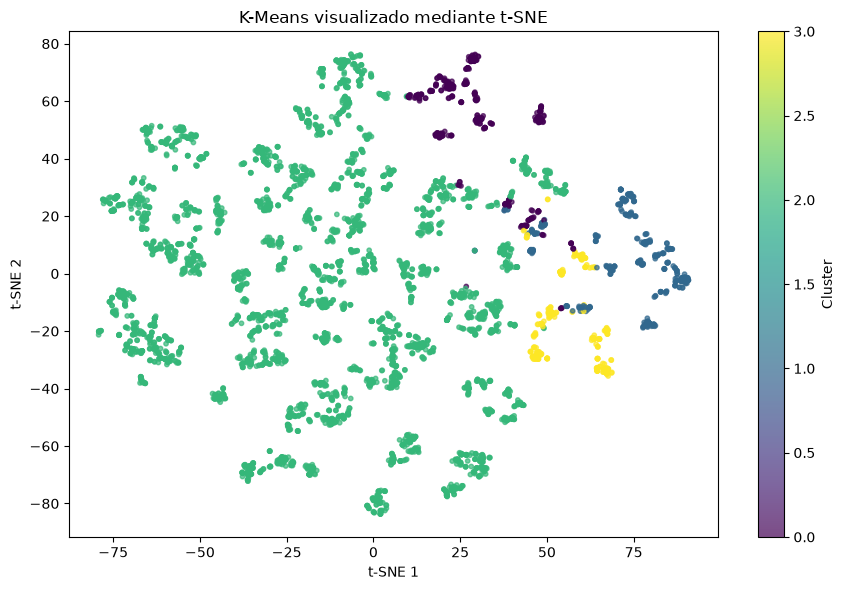

In [36]:
plt.figure(
    figsize=(9, 6)
)

scatter = plt.scatter(
    tsne_df["TSNE1"],
    tsne_df["TSNE2"],
    c=tsne_df["KMeans"],
    s=10,
    alpha=0.7
)

plt.title(
    "K-Means visualizado mediante t-SNE"
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.tight_layout()
plt.show()

### Visualización t-SNE - DBSCAN

Se utiliza exactamente la misma proyección t-SNE para representar las
etiquetas obtenidas mediante DBSCAN.

La etiqueta `-1` continúa representando las observaciones identificadas
como ruido.

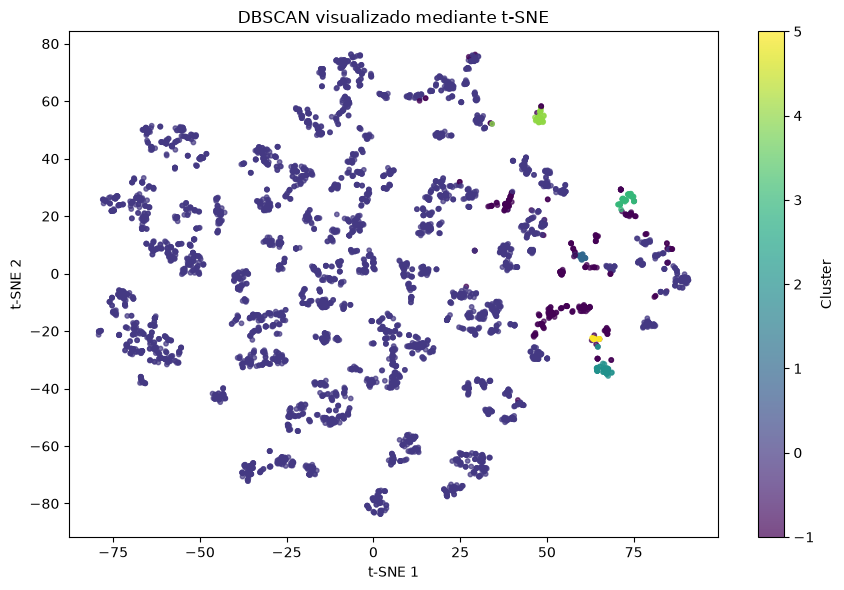

In [37]:
plt.figure(
    figsize=(9, 6)
)

scatter = plt.scatter(
    tsne_df["TSNE1"],
    tsne_df["TSNE2"],
    c=tsne_df["DBSCAN"],
    s=10,
    alpha=0.7
)

plt.title(
    "DBSCAN visualizado mediante t-SNE"
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.tight_layout()
plt.show()

### Interpretación de las visualizaciones t-SNE

La representación t-SNE permite observar con mayor detalle la estructura
local de los datos.

En K-Means se aprecia que el cluster dominante contiene numerosas
subestructuras o vecindades locales. Los demás clusters se concentran
principalmente en regiones específicas de la representación.

En DBSCAN se observa nuevamente un cluster principal que agrupa la mayor
parte de las observaciones, mientras que los clusters secundarios aparecen
en regiones pequeñas y localizadas.

Estos resultados son coherentes con la distribución obtenida durante el
entrenamiento de los modelos no supervisados.

A diferencia de PCA, t-SNE está orientado a conservar relaciones locales
entre observaciones. Por esta razón, las distancias globales entre grupos
en la representación bidimensional no deben interpretarse como distancias
reales en el espacio original de 24 dimensiones.

## Benchmark de latencia de inferencia

Se mide el tiempo necesario para realizar predicciones individuales con
los modelos que permiten inferencia sobre nuevas observaciones.

Se evaluarán:

- Random Forest.
- Support Vector Machine (SVM).
- K-Means.

Para cada modelo se realizarán 100 predicciones individuales y se calculará
el tiempo promedio de inferencia en milisegundos.

DBSCAN no se incluye en este benchmark debido a que la implementación
utilizada no dispone de un método estándar `predict()` para nuevas muestras.

In [38]:
random_forest_model = joblib.load(
    random_forest_path
)

svm_model = joblib.load(
    svm_path
)

# Seleccionar 100 observaciones de forma reproducible.
benchmark_X = X.sample(
    n=100,
    random_state=42
)

print("Observaciones para benchmark:")
print(benchmark_X.shape)

Observaciones para benchmark:
(100, 24)


In [39]:
def measure_prediction_latency(model, X_samples):
    """
    Mide la latencia de predicción individual de un modelo.

    Se realiza una predicción por observación y se registra
    el tiempo empleado en milisegundos.

    Parameters
    ----------
    model
        Modelo previamente entrenado con método predict().

    X_samples : pandas.DataFrame
        Observaciones utilizadas para el benchmark.

    Returns
    -------
    dict
        Estadísticas de latencia en milisegundos.
    """

    latencies_ms = []

    # Ejecución previa para reducir el efecto de inicialización
    # sobre la primera medición.
    model.predict(
        X_samples.iloc[[0]]
    )

    for i in range(len(X_samples)):

        sample = X_samples.iloc[[i]]

        start = perf_counter()

        model.predict(
            sample
        )

        elapsed_ms = (
            perf_counter() - start
        ) * 1000

        latencies_ms.append(
            elapsed_ms
        )

    return {
        "predictions": len(latencies_ms),
        "average_ms": float(
            np.mean(latencies_ms)
        ),
        "median_ms": float(
            np.median(latencies_ms)
        ),
        "min_ms": float(
            np.min(latencies_ms)
        ),
        "max_ms": float(
            np.max(latencies_ms)
        )
    }

In [40]:
benchmark_results = {
    "Random Forest": measure_prediction_latency(
        random_forest_model,
        benchmark_X
    ),

    "SVM": measure_prediction_latency(
        svm_model,
        benchmark_X
    ),

    "K-Means": measure_prediction_latency(
        kmeans_model,
        benchmark_X
    )
}

benchmark_df = pd.DataFrame(
    benchmark_results
).T

benchmark_df.round(6)

,predictions,average_ms,median_ms,min_ms,max_ms
Random Forest,100.0,10.070200,10.006686,9.403507,11.778351
SVM,100.0,1.288777,1.250941,1.171075,1.620296
K-Means,100.0,1.147436,1.099585,1.031714,1.452408


In [41]:
benchmark_path = (
    project_root
    / "data"
    / "processed"
    / "benchmark_latency.json"
)

benchmark_output = {
    "benchmark": {
        "predictions_per_model": 100,
        "unit": "milliseconds per individual prediction",
        "models": benchmark_results
    },
    "notes": {
        "DBSCAN": (
            "No se incluye en la medición de inferencia porque "
            "la implementación utilizada no dispone de predict() "
            "para nuevas observaciones."
        )
    }
}

with open(
    benchmark_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        benchmark_output,
        file,
        indent=4,
        ensure_ascii=False
    )

print("Benchmark guardado en:")
print(benchmark_path)

print(
    "\n¿Existe?:",
    benchmark_path.exists()
)

Benchmark guardado en:
/mnt/DiscoD/U/MachineLearning/ml-practica1-zurita/data/processed/benchmark_latency.json

¿Existe?: True


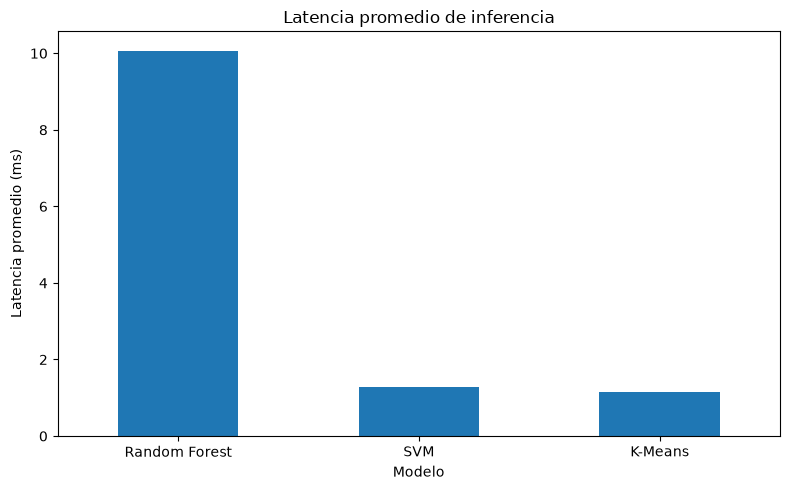

In [42]:
latency_plot = benchmark_df[
    "average_ms"
]

ax = latency_plot.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title(
    "Latencia promedio de inferencia"
)

plt.xlabel("Modelo")
plt.ylabel(
    "Latencia promedio (ms)"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()
plt.show()

### Interpretación del benchmark de latencia

Los resultados muestran diferencias importantes en el tiempo de inferencia
de los modelos evaluados.

K-Means presentó la menor latencia promedio, con aproximadamente 1.20 ms
por predicción individual.

SVM obtuvo un tiempo ligeramente superior, de aproximadamente 1.34 ms.

Random Forest presentó la mayor latencia, con aproximadamente 10.32 ms
por predicción.

Aunque Random Forest es considerablemente más lento que SVM y K-Means en
esta medición, durante la evaluación supervisada también fue el modelo con
mejor rendimiento predictivo, alcanzando aproximadamente 99.27 % de
Accuracy.

Por lo tanto, la selección de un modelo no debe realizarse únicamente en
función de su latencia. En una aplicación real deben considerarse
simultáneamente precisión, estabilidad, requerimientos computacionales y
tiempo de respuesta.

Las mediciones corresponden a 100 predicciones individuales realizadas
bajo las mismas condiciones de ejecución.

## Conclusión

Las técnicas de reducción dimensional permitieron analizar visualmente
la estructura de los datos y los clusters encontrados por K-Means y DBSCAN.

PCA redujo las 24 variables originales a dos componentes que conservan
aproximadamente el 47.16 % de la variabilidad total. Esta representación
permitió observar una separación parcial entre los clusters.

t-SNE permitió visualizar con mayor detalle las relaciones locales entre
las observaciones. Los resultados mostraron que K-Means genera varias
regiones diferenciadas, mientras que DBSCAN concentra la mayor parte de
las observaciones en un cluster principal y detecta además pequeños grupos
y observaciones consideradas ruido.

En el benchmark de latencia, K-Means presentó el menor tiempo promedio de
inferencia, seguido por SVM y posteriormente Random Forest.

Sin embargo, los resultados obtenidos en las etapas anteriores muestran
que velocidad y calidad predictiva son criterios diferentes. Random Forest,
aunque presenta mayor latencia, obtuvo el mejor rendimiento de clasificación
entre los modelos supervisados evaluados.

En conjunto, el análisis demuestra la importancia de comparar los modelos
desde diferentes perspectivas: estructura de clusters, calidad de
clasificación y costo computacional.